# Лабораторная работа №3
**Выполнил Недугов Владимир 6231-010402D**

# Генерация текстового описания к изображению
Всестороннее понимание зрения и языка и их взаимосвязей имеет решающее значение для понимания основных сходств и различий между этими модальностями и для изучения более обобщенных, значимых представлений. Автоматическая генерация описаний к изображениям может помогать исследователям в разметке данных, сокращать трудозатраты к описанию больших наборов изображений в каталогах и т.д.

## Постановка задачи
На вход подается изображение, содержащее некую смысловую нагрузку. На выходе получается описание на естественном языке исходного изображения.

Вход: Изображение низкого разрешения в формате .png, .bmp, .jpg

Выход: Текстовое описание исходного изображения на естественном языке.

## Пример набора данных
• https://vizwiz.org/tasks-and-datasets/image-captioning/

• https://storage.googleapis.com/openimages/web/index.html

## Предлагаемые архитектуры
• https://arxiv.org/abs/2112.04928


**Решение:** предобученная **BLIP (image encoder + text decoder)** с дообучение на **Flickr8k**.

Подписи датасета английские, поэтому генерация тоже на английском.

## 1. Установка и импорты

In [ ]:
%pip install -q "transformers>=4.45,<5" "datasets>=3,<5" "huggingface_hub>=0.30" "numpy<3" pandas Pillow matplotlib tqdm "nltk==3.9.2" "pycocoevalcap==1.2"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 42.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.3/104.3 MB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 84.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 33.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 82.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [ ]:
import json
import random
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from tqdm.auto import tqdm

import torch
from torch.utils.data import Dataset, DataLoader
from transformers import BlipProcessor, BlipForConditionalGeneration
from datasets import load_dataset
from nltk.tokenize import TreebankWordTokenizer
from nltk.translate.meteor_score import meteor_score
from pycocoevalcap.bleu.bleu import Bleu
from pycocoevalcap.rouge.rouge import Rouge
from pycocoevalcap.cider.cider import Cider

SEED = 42
HF_DATASET = "intro/flickr8k"
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Устройство:", DEVICE)

Устройство: cuda


## 2. Конфигурация

In [ ]:
TRAIN_LIMIT = 1600
DEV_LIMIT = 200
TEST_LIMIT = 200

MODEL_NAME = "Salesforce/blip-image-captioning-base"
DATA_ROOT = Path("/content/data/flickr8k_mini" if Path("/content").exists() else "data/flickr8k_mini")
OUTPUT_DIR = Path("/content/blip_flickr8k" if Path("/content").exists() else "blip_flickr8k")
DATA_SIZE = (256, 256)
BATCH_SIZE = 2
GRAD_ACCUM = 8
EPOCHS = 4
LEARNING_RATE = 2e-5
MAX_TEXT_LENGTH = 40
NUM_BEAMS = 3
NUM_WORKERS = 0
FREEZE_VISION_ENCODER = True  # дообучаем декодер; экономим VRAM
FORMATS = {".png", ".bmp", ".jpg", ".jpeg"}
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_ROOT.mkdir(parents=True, exist_ok=True)

## 3. Flickr8k: загрузка и train/dev/test

Берём пять оригинальных подписей на каждое изображение. На обучении используется **каждая** подпись, на dev/test все пять служат эталонами. Кэш изображений совместим с исходным ноутбуком.

In [ ]:
def words(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?|[0-9]+", text.lower())


def read_image(source):
    record = source if isinstance(source, dict) else {"path": Path(source)}
    with Image.open(record["path"]) as image:
        image = ImageOps.exif_transpose(image).convert("RGB")
        return image.copy()


def prepare_image(image):
    """Сохраняет пропорции; пустые края заполняет белым."""
    image = ImageOps.exif_transpose(image).convert("RGB")
    return ImageOps.pad(image, DATA_SIZE, method=Image.Resampling.LANCZOS, color=(255,255,255))


def local_records(split, limit):
    manifest = DATA_ROOT / split / "manifest.json"
    if manifest.is_file():
        raw = json.loads(manifest.read_text(encoding="utf-8"))
        if len(raw) >= limit and all((DATA_ROOT / item["path"]).is_file() for item in raw[:limit]):
            print(f"{split}: {limit} изображений уже в кэше")
            return [{**r, "path": DATA_ROOT / r["path"]} for r in raw[:limit]]
    return None


def download_flickr_split(streams, split, limit):
    if limit < 2:
        raise ValueError("Размер каждого split должен быть >= 2")
    found = local_records(split, limit)
    if found is not None:
        return found
    directory = DATA_ROOT / split
    directory.mkdir(parents=True, exist_ok=True)
    # shuffle(buffer_size) не требует скачивания всех 8000 фото;
    # ограниченное окно перемешивания делает выборку воспроизводимой.
    stream = streams[split].shuffle(seed=SEED, buffer_size=64)
    records = []
    for sample in tqdm(stream, total=limit, desc=f"Flickr8k {split}"):
        captions = [str(sample.get(f"caption_{i}") or "").strip() for i in range(5)]
        captions = [c for c in captions if c]
        if not captions:
            continue
        index = len(records)
        path = directory / f"{index:05d}.jpg"
        if not path.is_file():
            prepare_image(sample["image"]).save(path, format="JPEG", quality=85, optimize=True)
        records.append({"id": f"{split}_{index:05d}",
                        "path": str(path.relative_to(DATA_ROOT)),
                        "refs": captions, "class_id": None})
        if len(records) >= limit:
            break
    if len(records) < limit:
        raise RuntimeError(f"{split}: загрузилось только {len(records)} / {limit} изображений")
    (directory / "manifest.json").write_text(
        json.dumps(records, ensure_ascii=False, indent=2), encoding="utf-8")
    return [{**r, "path": DATA_ROOT / r["path"]} for r in records]


def get_flickr_records():
    limits = {"train": TRAIN_LIMIT, "dev": DEV_LIMIT, "test": TEST_LIMIT}
    cached = {split: local_records(split, limit) for split, limit in limits.items()}
    if all(value is not None for value in cached.values()):
        return cached["train"], cached["dev"], cached["test"]
    print("Читаем Flickr8k с Hugging Face в потоковом режиме...")
    try:
        streams = load_dataset(HF_DATASET, streaming=True)
    except Exception as exc:
        raise RuntimeError("Не удалось открыть Flickr8k. Проверьте доступ к huggingface.co") from exc
    return tuple(cached[split] if cached[split] is not None else
                 download_flickr_split(streams, split, limit)
                 for split, limit in limits.items())

In [ ]:
train_records, dev_records, test_records = get_flickr_records()
for name, records in [("train", train_records), ("dev", dev_records), ("test", test_records)]:
    print(f"{name}: {len(records)} изображений / {sum(len(r['refs']) for r in records)} подписей")

Читаем Flickr8k с Hugging Face в потоковом режиме...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

Resolving data files:   0%|          | 0/6001 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/1001 [00:00<?, ?it/s]

...

Resolving data files:   0%|          | 0/1001 [00:00<?, ?it/s]

Flickr8k train:   0%|          | 0/1600 [00:00<?, ?it/s]

Flickr8k dev:   0%|          | 0/200 [00:00<?, ?it/s]

Flickr8k test:   0%|          | 0/200 [00:00<?, ?it/s]

train: 1600 изображений / 8000 подписей
dev: 200 изображений / 1000 подписей
test: 200 изображений / 1000 подписей


## 4. BLIP

`BlipProcessor` масштабирует и нормализует исходные изображения под vision encoder. Модель уже обучена генерировать подписи; при fine-tuning обучаем **текстовый декодер**, заморозив vision encoder. Это намного проще и экономнее GAN-архитектуры.

In [ ]:
processor = BlipProcessor.from_pretrained(MODEL_NAME)
model = BlipForConditionalGeneration.from_pretrained(MODEL_NAME).to(DEVICE)
if FREEZE_VISION_ENCODER:
    for parameter in model.vision_model.parameters():
        parameter.requires_grad_(False)
print("Обучаемых параметров:", f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/990M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/990M [00:00<?, ?B/s]

Обучаемых параметров: 137,881,148


In [ ]:
class CaptionDataset(Dataset):
    def __init__(self, records, all_captions=True):
        self.pairs = [
            (record["path"], caption)
            for record in records
            for caption in (record["refs"] if all_captions else record["refs"][:1])
        ]

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):
        path, text = self.pairs[index]
        with Image.open(path) as source:
            image = ImageOps.exif_transpose(source).convert("RGB").copy()
        return image, text


def collate_captions(batch):
    images, captions = zip(*batch)
    enc = processor(images=list(images), text=list(captions),
                    padding="max_length", truncation=True,
                    max_length=MAX_TEXT_LENGTH, return_tensors="pt")
    labels = enc["input_ids"].clone()
    labels[labels == processor.tokenizer.pad_token_id] = -100
    return {"pixel_values": enc["pixel_values"], "input_ids": enc["input_ids"],
            "attention_mask": enc["attention_mask"], "labels": labels}

train_loader = DataLoader(CaptionDataset(train_records), batch_size=BATCH_SIZE,
                          shuffle=True, collate_fn=collate_captions,
                          num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"))
dev_loader = DataLoader(CaptionDataset(dev_records, all_captions=False),
                        batch_size=BATCH_SIZE, shuffle=False,
                        collate_fn=collate_captions, num_workers=NUM_WORKERS)
print("Train batches:", len(train_loader), "Dev batches:", len(dev_loader))

Train batches: 4000 Dev batches: 100


## 5. Fine-tuning и выбор лучшей эпохи

Обучение использует cross-entropy следующего токена по истинной подписи.

  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

Эпоха 1/4: train=2.1369, dev=1.9276
  Сохранён лучший checkpoint: /content/blip_flickr8k


  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

...

  0%|          | 0/100 [00:00<?, ?it/s]

Эпоха 3/4: train=1.3852, dev=1.9535


  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

Эпоха 4/4: train=1.1779, dev=2.0599


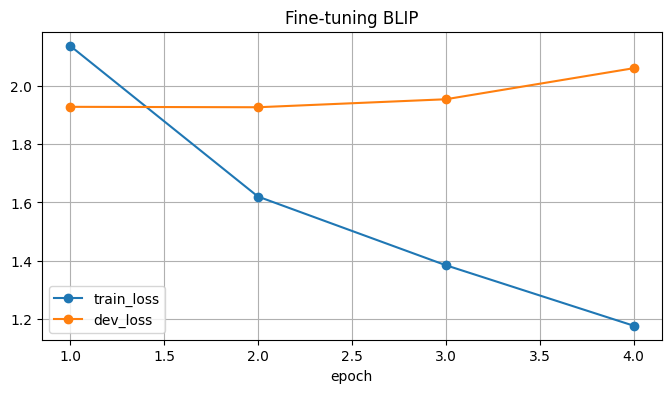

In [ ]:
optimizer = torch.optim.AdamW((p for p in model.parameters() if p.requires_grad), lr=LEARNING_RATE)
scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda"))


def epoch_loss(data_loader, training=False):
    model.train(training)
    if FREEZE_VISION_ENCODER:
        model.vision_model.eval()
    total_loss, total_items = 0.0, 0
    optimizer.zero_grad(set_to_none=True)
    for step, batch in enumerate(tqdm(data_loader, leave=False)):
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        with torch.set_grad_enabled(training):
            with torch.autocast("cuda", enabled=DEVICE.type == "cuda"):
                loss = model(**batch).loss
            if training:
                scaler.scale(loss / GRAD_ACCUM).backward()
                if (step + 1) % GRAD_ACCUM == 0 or (step + 1) == len(data_loader):
                    scaler.unscale_(optimizer)
                    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    scaler.step(optimizer)
                    scaler.update()
                    optimizer.zero_grad(set_to_none=True)
        n = batch["pixel_values"].size(0)
        total_loss += loss.detach().item() * n
        total_items += n
    return total_loss / max(total_items, 1)

history = []
best_dev_loss = float("inf")
for epoch in range(1, EPOCHS + 1):
    train_loss = epoch_loss(train_loader, training=True)
    dev_loss = epoch_loss(dev_loader, training=False)
    history.append({"epoch": epoch, "train_loss": train_loss, "dev_loss": dev_loss})
    print(f"Эпоха {epoch}/{EPOCHS}: train={train_loss:.4f}, dev={dev_loss:.4f}")
    if dev_loss < best_dev_loss:
        best_dev_loss = dev_loss
        model.save_pretrained(OUTPUT_DIR)
        processor.save_pretrained(OUTPUT_DIR)
        print("  Сохранён лучший checkpoint:", OUTPUT_DIR)

pd.DataFrame(history).set_index("epoch").plot(marker="o", figsize=(8, 4), grid=True,
                                              title="Fine-tuning BLIP")
plt.show()

## 6. Проверка качества на test

In [ ]:
# Загружаем именно лучший checkpoint, выбранный на dev
model = BlipForConditionalGeneration.from_pretrained(OUTPUT_DIR).to(DEVICE).eval()
processor = BlipProcessor.from_pretrained(OUTPUT_DIR)

@torch.inference_mode()
def predict_captions(records, batch_size=BATCH_SIZE):
    captions = []
    for start in tqdm(range(0, len(records), batch_size), desc="Captioning"):
        images = [read_image(item) for item in records[start:start + batch_size]]
        pixel_values = processor(images=images, return_tensors="pt")["pixel_values"].to(DEVICE)
        generated = model.generate(pixel_values=pixel_values, num_beams=NUM_BEAMS,
                                   max_new_tokens=MAX_TEXT_LENGTH)
        captions.extend(processor.batch_decode(generated, skip_special_tokens=True))
    return captions

tokenizer = TreebankWordTokenizer()
def metric_tokens(text):
    return tokenizer.tokenize(" ".join(text.lower().split()), convert_parentheses=True)

def caption_metrics(predictions, records):
    assert len(predictions) == len(records)
    gt = {i: [" ".join(metric_tokens(ref)) for ref in rec["refs"]]
          for i, rec in enumerate(records)}
    pred = {i: [" ".join(metric_tokens(text))] for i, text in enumerate(predictions)}
    result = {}
    for scorer, names in [(Bleu(4), ["BLEU-1", "BLEU-2", "BLEU-3", "BLEU-4"]),
                          (Rouge(), ["ROUGE-L"]), (Cider(), ["CIDEr"])]:
        score, _ = scorer.compute_score(gt, pred)
        scores = score if isinstance(score, (list, tuple, np.ndarray)) else [score]
        result.update({name: float(v) for name, v in zip(names, scores)})
    try:
        result["METEOR"] = float(np.mean([
            meteor_score([metric_tokens(ref) for ref in r["refs"]], metric_tokens(p))
            for p, r in zip(predictions, records)
        ]))
    except LookupError:
        import nltk
        nltk.download("wordnet", quiet=True)
        nltk.download("omw-1.4", quiet=True)
        result["METEOR"] = float(np.mean([
            meteor_score([metric_tokens(ref) for ref in r["refs"]], metric_tokens(p))
            for p, r in zip(predictions, records)
        ]))
    return result

test_predictions = predict_captions(test_records)
results = pd.DataFrame([{"model": "BLIP fine-tuned on Flickr8k",
                         **caption_metrics(test_predictions, test_records)}])
display(results.round(4))
results.to_csv(OUTPUT_DIR / "test_metrics.csv", index=False)

Captioning:   0%|          | 0/100 [00:00<?, ?it/s]

{'testlen': 2118, 'reflen': 2128, 'guess': [2118, 1918, 1718, 1518], 'correct': [1630, 889, 473, 230]}
ratio: 0.9953007518792315


,model,BLEU-1,BLEU-2,BLEU-3,BLEU-4,ROUGE-L,CIDEr,METEOR
0,BLIP fine-tuned on Flickr8k,0.766,0.5944,0.4592,0.3476,0.5857,0.9918,0.5376


## 7. Примеры результатов на тестовых изображениях

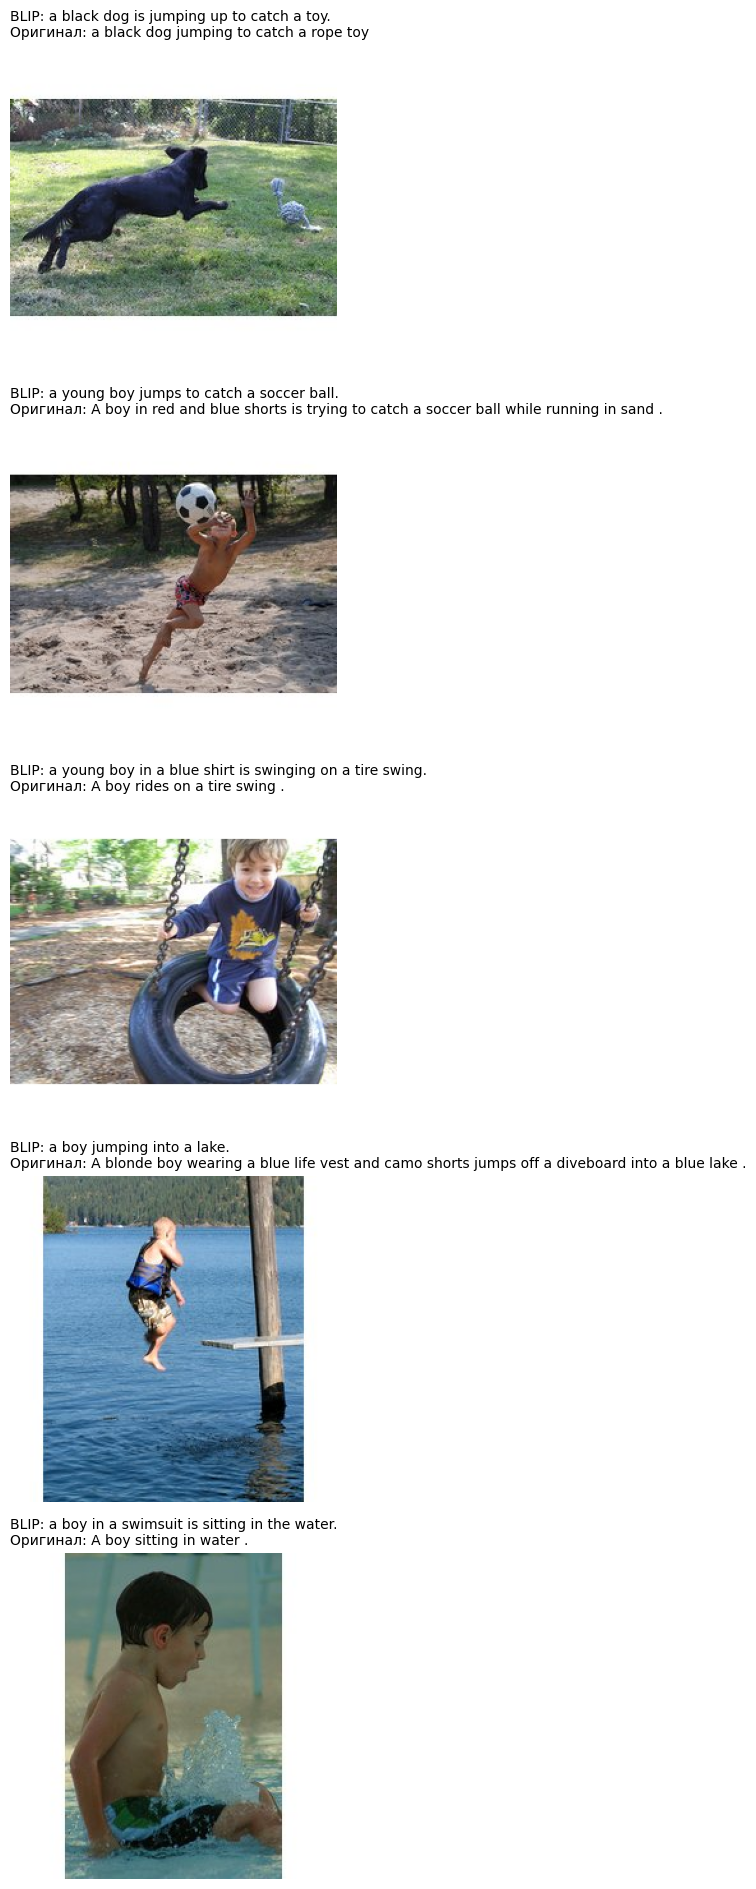

In [ ]:
count = min(5, len(test_records))
fig, axes = plt.subplots(count, 1, figsize=(12, 3.8 * count))
if count == 1:
    axes = [axes]
for i, ax in enumerate(axes):
    ax.imshow(read_image(test_records[i]))
    ax.axis("off")
    ax.set_title("BLIP: " + test_predictions[i] + "\nОригинал: " + test_records[i]["refs"][0],
                 fontsize=10, loc="left")
plt.tight_layout()
plt.show()